In [1]:
import pandas as pd

netflix = pd.read_csv("Dataset.csv")

netflix.head()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [2]:
netflix.shape

(8790, 10)

In [3]:
netflix.info()

<class 'pandas.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8790 non-null   str  
 1   type          8790 non-null   str  
 2   title         8790 non-null   str  
 3   director      8790 non-null   str  
 4   country       8790 non-null   str  
 5   date_added    8790 non-null   str  
 6   release_year  8790 non-null   int64
 7   rating        8790 non-null   str  
 8   duration      8790 non-null   str  
 9   listed_in     8790 non-null   str  
dtypes: int64(1), str(9)
memory usage: 1.6 MB


In [4]:
netflix.isnull().sum()

show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64

In [5]:
netflix.duplicated().sum()

np.int64(0)

In [6]:
netflix["show_id"].duplicated().sum()

np.int64(0)

In [7]:
netflix["type"].value_counts()

type
Movie      6126
TV Show    2664
Name: count, dtype: int64

In [8]:
netflix["rating"].value_counts()

rating
TV-MA       3205
TV-14       2157
TV-PG        861
R            799
PG-13        490
TV-Y7        333
TV-Y         306
PG           287
TV-G         220
NR            79
G             41
TV-Y7-FV       6
NC-17          3
UR             3
Name: count, dtype: int64

In [9]:
text_columns=netflix.select_dtypes(include="str").columns
for col in text_columns:
    print(col, netflix[col].ne(netflix[col].str.strip()).sum())

show_id 0
type 0
title 1
director 0
country 0
date_added 0
rating 0
duration 0
listed_in 0


In [10]:
pd.to_datetime(netflix["date_added"],errors="coerce").isna().sum()

np.int64(0)

In [11]:
netflix.loc[netflix["title"]!=netflix["title"].str.strip(),"title"]

4718    Consequences 
Name: title, dtype: str

In [12]:
for col in text_columns:
    netflix[col]=netflix[col].str.strip()
print(netflix[col])

0                                           Documentaries
1       Crime TV Shows, International TV Shows, TV Act...
2                      TV Dramas, TV Horror, TV Mysteries
3                      Children & Family Movies, Comedies
4        Dramas, Independent Movies, International Movies
                              ...                        
8785                    International TV Shows, TV Dramas
8786                                             Kids' TV
8787    International TV Shows, Romantic TV Shows, TV ...
8788                                             Kids' TV
8789                                             Kids' TV
Name: listed_in, Length: 8790, dtype: str


In [13]:
netflix["date_added"]=pd.to_datetime(netflix["date_added"])
print(netflix["date_added"])

0      2021-09-25
1      2021-09-24
2      2021-09-24
3      2021-09-22
4      2021-09-24
          ...    
8785   2017-01-17
8786   2018-09-13
8787   2016-12-15
8788   2018-06-23
8789   2018-06-07
Name: date_added, Length: 8790, dtype: datetime64[us]


In [14]:
netflix.info()

<class 'pandas.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   show_id       8790 non-null   str           
 1   type          8790 non-null   str           
 2   title         8790 non-null   str           
 3   director      8790 non-null   str           
 4   country       8790 non-null   str           
 5   date_added    8790 non-null   datetime64[us]
 6   release_year  8790 non-null   int64         
 7   rating        8790 non-null   str           
 8   duration      8790 non-null   str           
 9   listed_in     8790 non-null   str           
dtypes: datetime64[us](1), int64(1), str(8)
memory usage: 1.5 MB


In [15]:
text_columns = netflix.select_dtypes(include="str").columns

for col in text_columns:
    print(col, netflix[col].ne(netflix[col].str.strip()).sum())

show_id 0
type 0
title 0
director 0
country 0
rating 0
duration 0
listed_in 0


In [16]:
print("Shape:", netflix.shape)
print("Missing values:", netflix.isnull().sum().sum())
print("Duplicate rows:", netflix.duplicated().sum())
print("Duplicate IDs:", netflix["show_id"].duplicated().sum())

Shape: (8790, 10)
Missing values: 0
Duplicate rows: 0
Duplicate IDs: 0



## Task 1: Netflix Data Cleaning & Preparation

### Data Quality Checks
- Dataset size: 8,790 rows and 10 columns.
- No Pandas-detected null values were found.
- No exact duplicate rows were found.
- No duplicate show IDs were found.
- One title contained surrounding whitespace, which was removed.
- The date_added column was converted from string to datetime.
- Text columns were checked for leading and trailing whitespace.

### Conclusion
The dataset was checked for common data quality issues and prepared for further analysis. The original dataset contained no exact duplicate rows or Pandas-detected null values.


In [17]:
netflix.to_csv("Netflix_Cleaned.csv", index=False)

In [18]:
content_counts=netflix["type"].value_counts()
print(content_counts)

type
Movie      6126
TV Show    2664
Name: count, dtype: int64


In [19]:
netflix["type"].value_counts(normalize=True)

type
Movie      0.696928
TV Show    0.303072
Name: proportion, dtype: float64

In [20]:
content_percentages=netflix["type"].value_counts(normalize=True)*100
print(content_percentages.round(2))

type
Movie      69.69
TV Show    30.31
Name: proportion, dtype: float64


In [21]:
content_summary=pd.DataFrame({
    "Count": content_counts,
    "Percentage": content_percentages.round(2)
})
print(content_summary)

         Count  Percentage
type                      
Movie     6126       69.69
TV Show   2664       30.31


In [22]:
import matplotlib.pyplot as plt

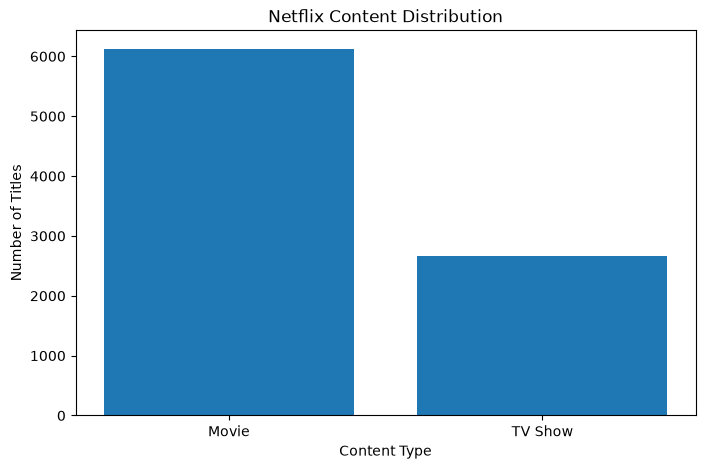

In [23]:
plt.figure(figsize=(8, 5))

plt.bar(content_counts.index, content_counts.values)

plt.title("Netflix Content Distribution")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")

plt.show()

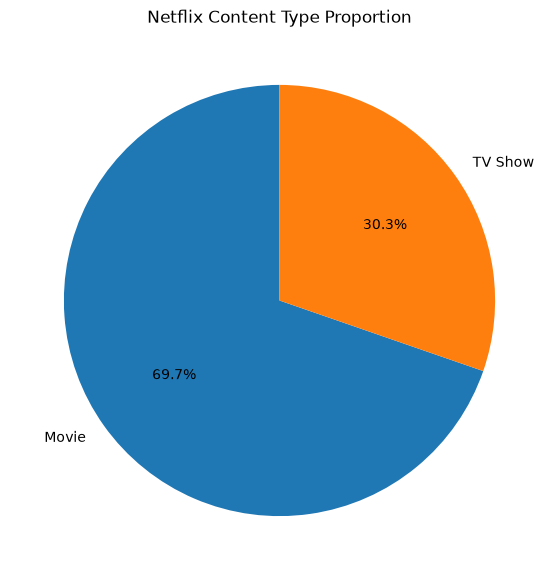

In [24]:
plt.figure(figsize=(7, 7))

plt.pie(
    content_counts.values,
    labels=content_counts.index,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Netflix Content Type Proportion")
plt.show()

## Task 2: Content Type Analysis

- Total titles analysed: 8,790
- Movies: 6,126 (69.69%)
- TV Shows: 2,664 (30.31%)

### Key Finding

Movies account for the majority of titles in the dataset, representing approximately 69.69% of the catalogue. TV Shows account for the remaining 30.31%.


In [25]:
netflix["country"].value_counts().head(10)

country
United States     3240
India             1057
United Kingdom     638
Pakistan           421
Not Given          287
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Name: count, dtype: int64

In [26]:
netflix.loc[
    netflix["country"].str.contains(",", regex=False),
    "country"
].head(10)

Series([], Name: country, dtype: str)

In [27]:
netflix["country"].str.contains(",", regex=False).sum()

np.int64(0)

In [28]:
netflix["country"].nunique()

86

In [29]:
netflix["country"].value_counts().tail(15)

country
Zimbabwe        1
Paraguay        1
Soviet Union    1
Greece          1
West Germany    1
Iran            1
Slovenia        1
Guatemala       1
Jamaica         1
Somalia         1
Luxembourg      1
Senegal         1
Belarus         1
Puerto Rico     1
Cyprus          1
Name: count, dtype: int64

In [30]:
(netflix["country"]=="Not Given").sum()

np.int64(287)

In [31]:
country_counts=netflix.loc[
    netflix["country"]!="Not Given",
    "country"
].value_counts()
country_counts.head(10)

country
United States     3240
India             1057
United Kingdom     638
Pakistan           421
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Mexico             138
Name: count, dtype: int64

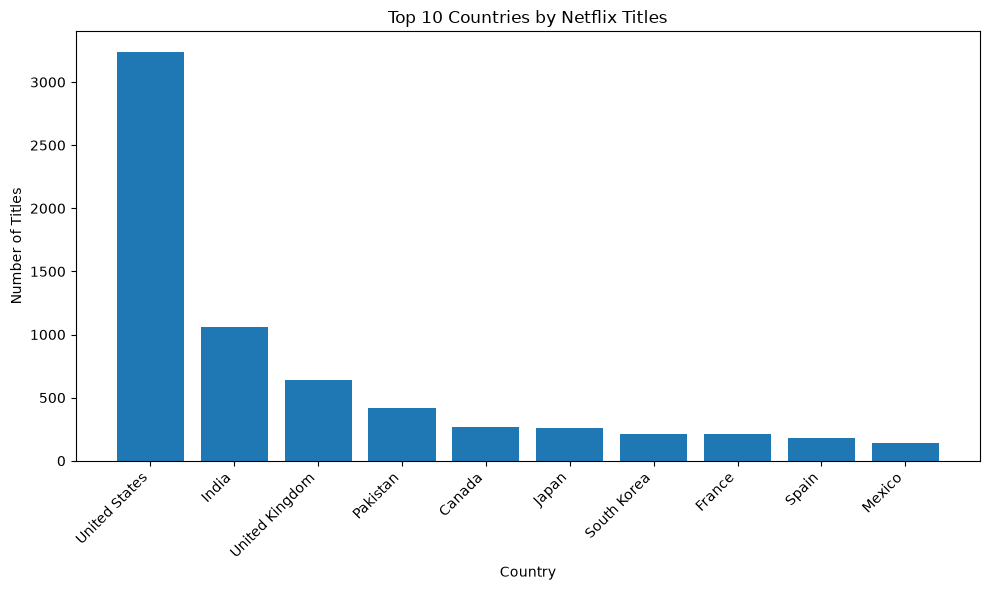

In [32]:
import matplotlib.pyplot as plt 

top_10_countries=country_counts.head(10)

plt.figure(figsize=(10, 6))
plt.bar(top_10_countries.index, top_10_countries.values)

plt.title("Top 10 Countries by Netflix Titles") 
plt.xlabel("Country")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()


## Task 3: Country-Wise Netflix Content Analysis

### Key Findings
- The dataset contains 86 distinct country entries, including the "Not Given" placeholder.
- The United States ranks first with 3,240 titles.
- India ranks second with 1,057 titles.
- The United Kingdom ranks third with 638 titles.
- There are 287 records labelled "Not Given", which were excluded from the ranking.

### Business Insight
The United States has the largest representation in the supplied dataset, followed by India and the United Kingdom. These rankings describe the country entries as provided in the dataset.


In [33]:
year_counts=netflix["release_year"].value_counts().sort_index()
year_counts.head()

release_year
1925    1
1942    2
1943    3
1944    3
1945    4
Name: count, dtype: int64

In [34]:
year_counts.sort_values(ascending=False).head(10)

release_year
2018    1146
2017    1030
2019    1030
2020     953
2016     901
2021     592
2015     555
2014     352
2013     286
2012     236
Name: count, dtype: int64

In [35]:
netflix["release_year"].max()

np.int64(2021)

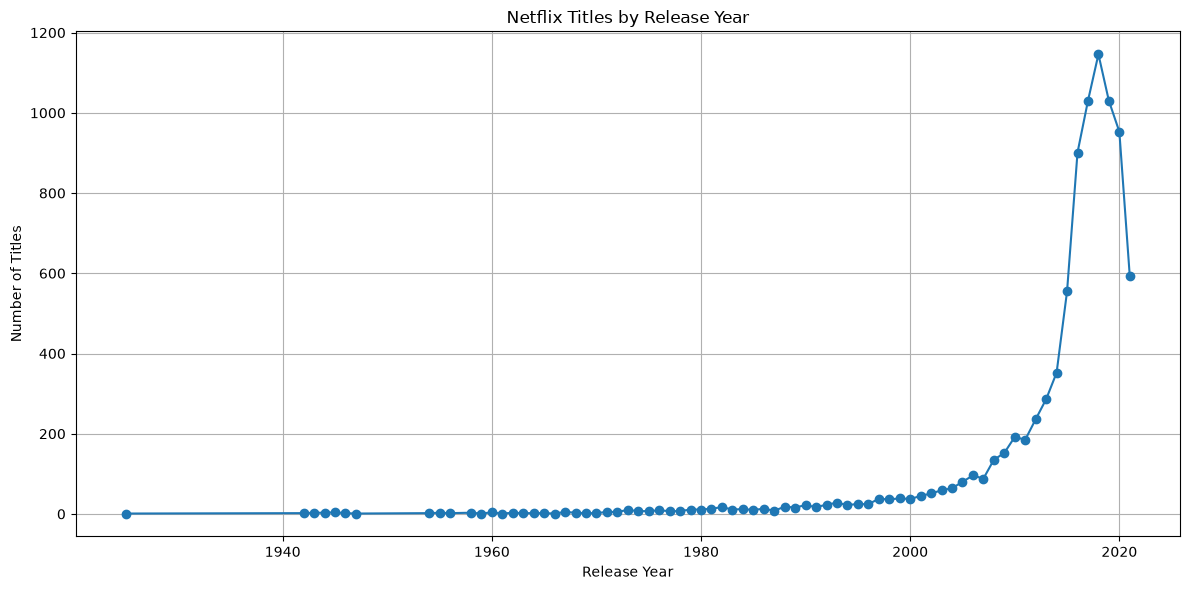

In [36]:
plt.figure(figsize=(12, 6))

plt.plot(year_counts.index, year_counts.values, marker="o")

plt.title("Netflix Titles by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")

plt.grid(True)
plt.tight_layout()
plt.show()


## Task 4: Trend Analysis by Release Year

### Key Findings
- The dataset contains titles released as early as 1925.
- The highest number of titles is associated with 2018, with 1,146 titles.
- The years 2017 and 2019 each have 1,030 titles.
- The number of titles decreases from 2019 to 2021 in this dataset.
- The latest release year represented is 2021.

### Business Insight
The dataset has a strong concentration of titles released in more recent years, with 2018 having the highest count. The decline in counts after 2019 describes the supplied dataset and does not, by itself, establish the reason for the trend.


In [40]:
rating_counts = netflix["rating"].value_counts()

print(rating_counts)

rating
TV-MA       3205
TV-14       2157
TV-PG        861
R            799
PG-13        490
TV-Y7        333
TV-Y         306
PG           287
TV-G         220
NR            79
G             41
TV-Y7-FV       6
NC-17          3
UR             3
Name: count, dtype: int64


In [41]:
top_ratings = rating_counts.head(5)

print(top_ratings)

rating
TV-MA    3205
TV-14    2157
TV-PG     861
R         799
PG-13     490
Name: count, dtype: int64


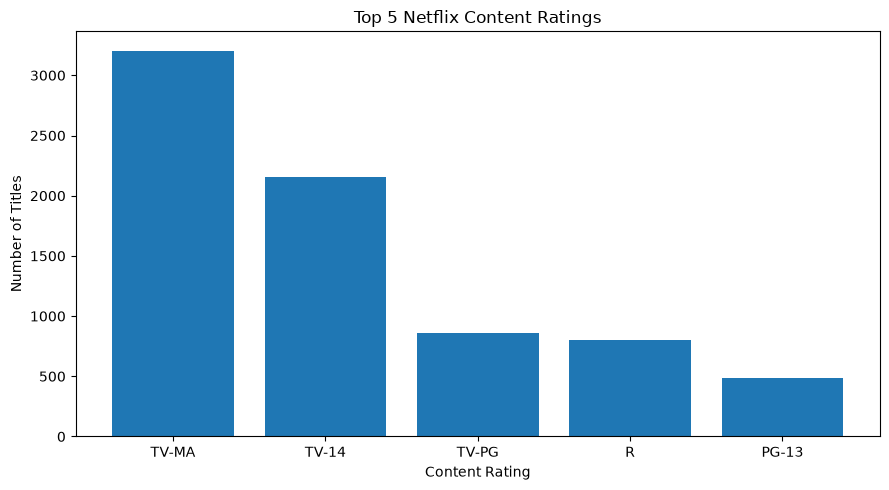

In [42]:
plt.figure(figsize=(9, 5))

plt.bar(top_ratings.index, top_ratings.values)

plt.title("Top 5 Netflix Content Ratings")
plt.xlabel("Content Rating")
plt.ylabel("Number of Titles")

plt.tight_layout()
plt.show()

In [43]:
genres = netflix["listed_in"].str.split(", ").explode()

genre_counts = genres.value_counts()

print(genre_counts.head(10))

listed_in
International Movies        2752
Dramas                      2426
Comedies                    1674
International TV Shows      1349
Documentaries                869
Action & Adventure           859
TV Dramas                    762
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64


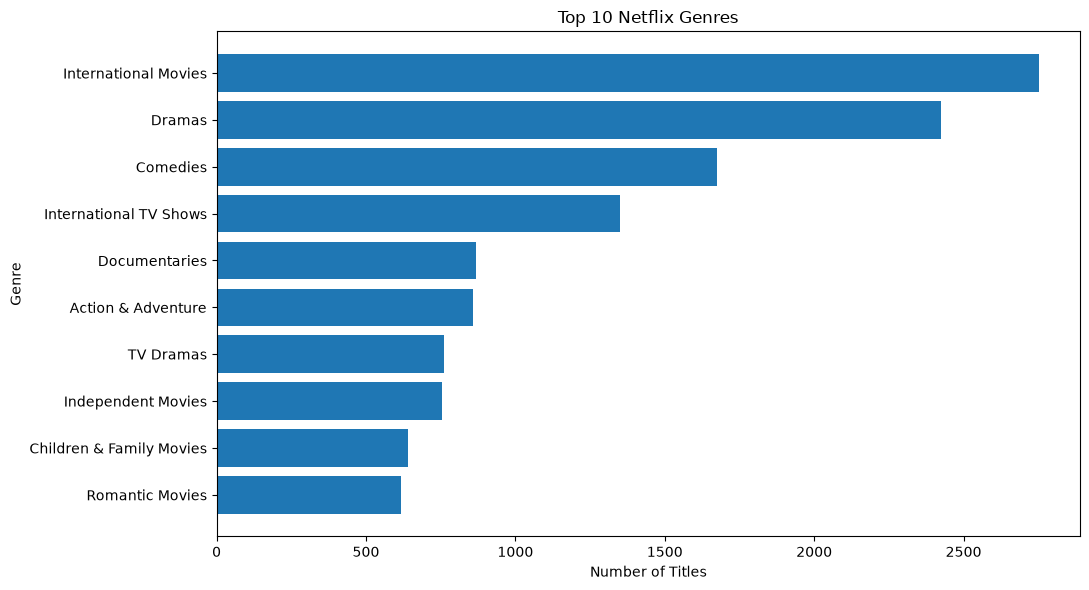

In [44]:
top_genres = genre_counts.head(10)

plt.figure(figsize=(11, 6))

plt.barh(top_genres.index, top_genres.values)

plt.title("Top 10 Netflix Genres")
plt.xlabel("Number of Titles")
plt.ylabel("Genre")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [45]:
rating_by_type = pd.crosstab(netflix["rating"], netflix["type"])

print(rating_by_type)

type      Movie  TV Show
rating                  
G            41        0
NC-17         3        0
NR           75        4
PG          287        0
PG-13       490        0
R           797        2
TV-14      1427      730
TV-G        126       94
TV-MA      2062     1143
TV-PG       540      321
TV-Y        131      175
TV-Y7       139      194
TV-Y7-FV      5        1
UR            3        0


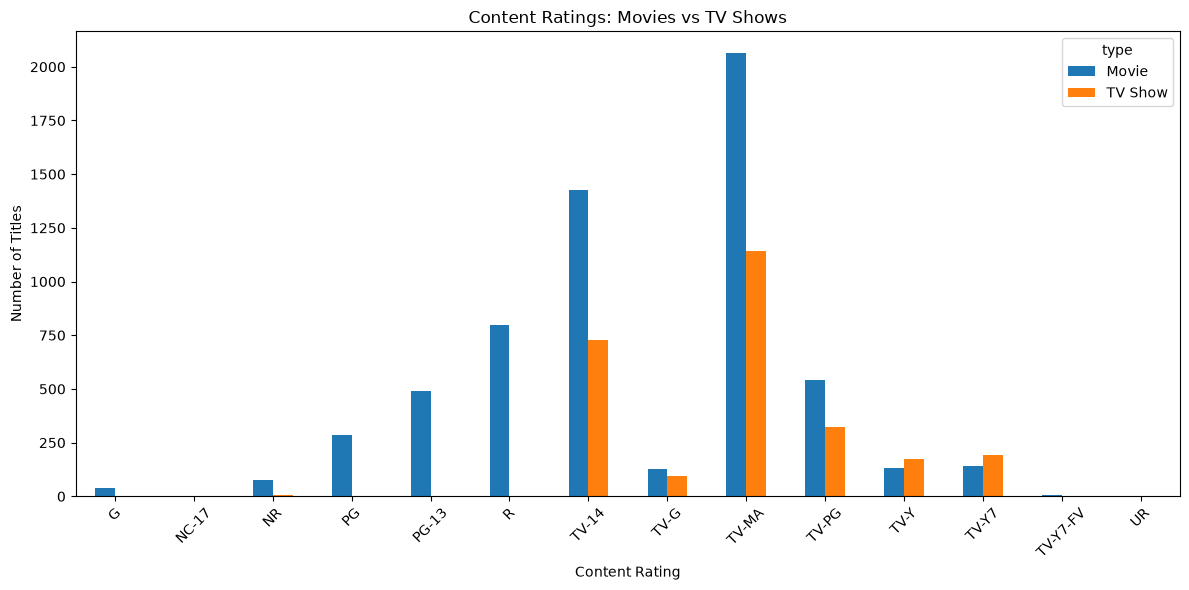

In [46]:
rating_by_type.plot(kind="bar", figsize=(12, 6))

plt.title("Content Ratings: Movies vs TV Shows")
plt.xlabel("Content Rating")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## Task 5: Content Rating & Genre Analysis

### Key Findings

- TV-MA is the most common content rating, with 3,205 titles.
- TV-14 is the second most common rating, with 2,157 titles.
- International Movies is the most frequent genre/category, with 2,752 appearances.
- Dramas ranks second with 2,426 appearances, followed by Comedies with 1,674.
- TV-MA is the most frequent rating for both Movies (2,062) and TV Shows (1,143).
- TV-Y has more TV Shows (175) than Movies (131).

### Business Insights

The dataset shows a strong presence of mature-rated content, particularly TV-MA and TV-14. International Movies, Dramas, and Comedies are the most frequent listed categories. These patterns may help describe the content mix and inform further audience analysis.

### Visualizations Created

- Bar chart of the top five content ratings.
- Horizontal bar chart of the top ten genres/categories.
- Grouped bar chart comparing ratings across Movies and TV Shows.


In [48]:
import plotly.express as px

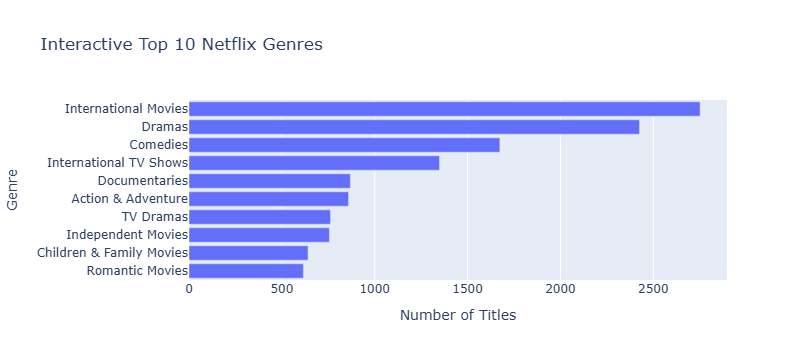

In [49]:
fig = px.bar(
    top_genres,
    x=top_genres.values,
    y=top_genres.index,
    orientation="h",
    title="Interactive Top 10 Netflix Genres",
    labels={
        "x": "Number of Titles",
        "y": "Genre"
    }
)

fig.update_layout(yaxis={"categoryorder": "total ascending"})

fig.show()

In [50]:
total_titles = len(netflix)
content_types = netflix["type"].nunique()
release_years = netflix["release_year"].nunique()
content_ratings = netflix["rating"].nunique()

print("NETFLIX BUSINESS OVERVIEW")
print("-------------------------")
print("Total titles:", total_titles)
print("Content types:", content_types)
print("Distinct release years:", release_years)
print("Distinct content ratings:", content_ratings)

print("\nMovies and TV Shows:")
print(netflix["type"].value_counts())

NETFLIX BUSINESS OVERVIEW
-------------------------
Total titles: 8790
Content types: 2
Distinct release years: 74
Distinct content ratings: 14

Movies and TV Shows:
type
Movie      6126
TV Show    2664
Name: count, dtype: int64


In [51]:
content_counts = netflix["type"].value_counts()

content_percentages = (content_counts / total_titles) * 100

business_overview = pd.DataFrame({
    "Count": content_counts,
    "Percentage": content_percentages.round(2)
})

print(business_overview)

         Count  Percentage
type                      
Movie     6126       69.69
TV Show   2664       30.31


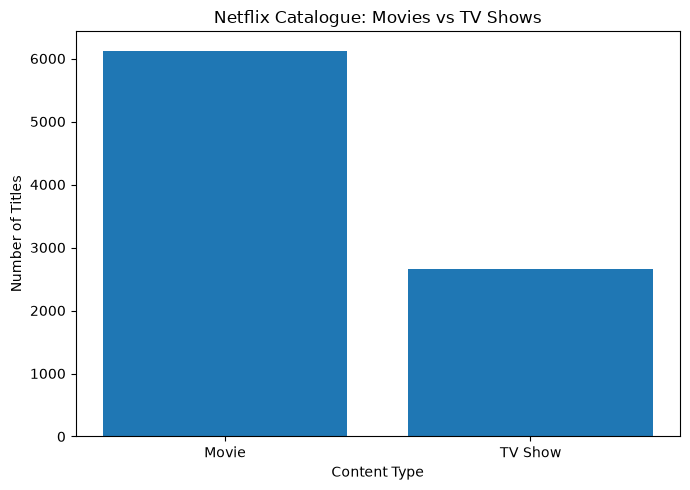

In [52]:
plt.figure(figsize=(7, 5))

plt.bar(
    business_overview.index,
    business_overview["Count"]
)

plt.title("Netflix Catalogue: Movies vs TV Shows")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")

plt.tight_layout()
plt.show()

In [53]:
top_release_years = year_counts.sort_values(
    ascending=False
).head(5)

print(top_release_years)

release_year
2018    1146
2017    1030
2019    1030
2020     953
2016     901
Name: count, dtype: int64


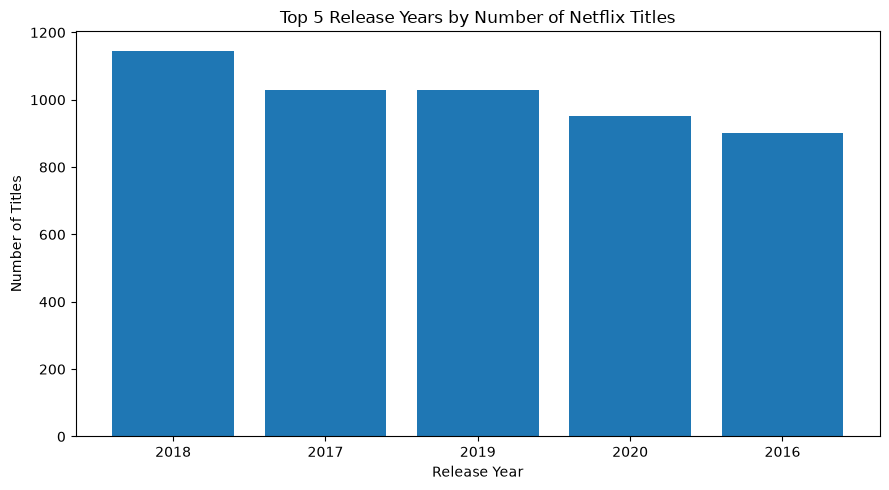

In [54]:
plt.figure(figsize=(9, 5))

plt.bar(
    top_release_years.index.astype(str),
    top_release_years.values
)

plt.title("Top 5 Release Years by Number of Netflix Titles")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")

plt.tight_layout()
plt.show()


# Task 6: Netflix Business Insights Report

## 1. Executive Summary

This project analysed 8,790 Netflix titles using Python, Pandas, Matplotlib, and Plotly. The analysis explored content types, country representation, release-year trends, content ratings, and genres.

## 2. Key Findings

### Content Distribution
- The dataset contains 8,790 titles.
- Movies account for 6,126 titles (69.69%).
- TV Shows account for 2,664 titles (30.31%).

### Country Representation
- The United States has the highest number of titles, with 3,240.
- India ranks second with 1,057 titles.
- The United Kingdom ranks third with 638 titles.
- 287 records are labelled "Not Given" for country.

### Release-Year Trends
- 2018 has the highest number of titles, with 1,146.
- 2017 and 2019 each have 1,030 titles.
- The dataset contains release years from 1925 through 2021.

### Ratings and Genres
- TV-MA is the most common rating, with 3,205 titles.
- TV-14 ranks second, with 2,157 titles.
- International Movies is the most frequent listed category, with 2,752 appearances.
- Dramas and Comedies follow, with 2,426 and 1,674 appearances respectively.

## 3. Business Insights

- Movies form the majority of the catalogue represented in this dataset.
- The United States, India, and the United Kingdom have the highest country counts.
- The concentration of titles in recent release years suggests that newer releases are strongly represented.
- Mature ratings and international categories are prominent in the dataset.

## 4. Recommendations

- Explore audience engagement by content type to understand whether Movies or TV Shows perform better.
- Investigate country-level viewing data before making regional investment decisions.
- Analyse genres alongside ratings to identify content combinations worth exploring.
- Continue checking data quality and documenting missing or placeholder values before further analysis.

## 5. Limitations

This dataset describes titles and their metadata, not viewing hours, audience engagement, revenue, or profitability. Therefore, it cannot establish which content performs best commercially or explain why certain categories are more common.

## 6. Tools Used

- Python
- Pandas
- Matplotlib
- Plotly
- JupyterLab

## 7. Conclusion

The analysis identified the main content types, leading country entries, common ratings and genres, and prominent release years in the supplied Netflix dataset. The findings provide a descriptive overview and a foundation for further business analysis.
